In [23]:
from diffusion_model import Model
import torch

Load a random input to test the model and its shape

In [19]:
x = torch.randn(4, 1, 32, 32)

print(x.shape)

torch.Size([4, 1, 32, 32])


In [13]:
model = Model(1, 32, 1, 2)

In [ ]:
c_noise = torch.randn(x.shape[0])  
y = model(x, c_noise)

print("Input:", x.shape)
print("Noise embedding:", model.noise_emb(c_noise).shape)
print("Output:", y.shape)

assert y.shape == x.shape

Input: torch.Size([4, 1, 32, 32])
Noise embedding: torch.Size([4, 2])
Output: torch.Size([4, 1, 32, 32])


Loading the datasets 

In [20]:
from data import load_dataset_and_make_dataloaders

dl, info = load_dataset_and_make_dataloaders(
    dataset_name="FashionMNIST",
    root_dir="data",
    batch_size=4,
)

y, labels = next(iter(dl.train))

print("Clean images:", y.shape)
print("Data standard deviation:", info.sigma_data)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 672kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 1.46MB/s]


Clean images: torch.Size([4, 1, 32, 32])
Data standard deviation: tensor(0.6622)


Add a noise to the images 
$x = y + \sigma \epsilon$

In [21]:
sigma = torch.tensor([0.05, 0.2, 0.5, 1.0])

eps = torch.randn_like(y)
s = sigma[:, None, None, None]

x = y + s * eps

print("Noise strengths:", sigma.shape)  # [4]
print("Broadcast strengths:", s.shape)   # [4, 1, 1, 1]
print("Pixel noise:", eps.shape)      # [4, 1, 32, 32]
print("Noisy images:", x.shape)           # [4, 1, 32, 32]

assert x.shape == y.shape

Noise strengths: torch.Size([4])
Broadcast strengths: torch.Size([4, 1, 1, 1])
Pixel noise: torch.Size([4, 1, 32, 32])
Noisy images: torch.Size([4, 1, 32, 32])


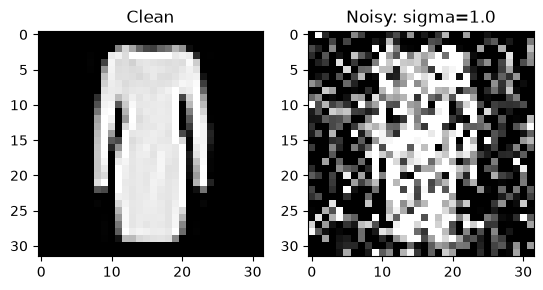

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2)

axes[0].imshow(y[3, 0], cmap="gray", vmin=-1, vmax=1)
axes[0].set_title("Clean")

axes[1].imshow(x[3, 0], cmap="gray", vmin=-1, vmax=1)
axes[1].set_title(f"Noisy: sigma={sigma[3].item()}")

plt.show()